# 1. Contexte métier et problématique

## 1.1 Contexte

TouNum est une entreprise spécialisée dans la numérisation de documents, notamment à partir de supports papier. Dans le cadre de l'augmentation du volume de documents numérisés, l'entreprise souhaite développer de nouveaux services reposant sur les techniques de Machine Learning.

L'un des objectifs du projet consiste à mettre en place une chaîne automatisée permettant d'analyser des images et, à terme, de générer automatiquement une légende descriptive de leur contenu.

Avant de réaliser cette étape de génération de légendes (*image captioning*), une étape de filtrage est nécessaire. En effet, l'ensemble des images numérisées par TouNum ne correspond pas nécessairement à des photographies. Le dataset peut également contenir des schémas, des graphiques, des textes scannés, des dessins ou encore des peintures.

L'objectif de ce premier livrable est donc de développer un modèle de classification capable de distinguer automatiquement :

* les **photographies** ;
* les **autres types d'images**.

Cette classification permettra de sélectionner automatiquement les photographies qui pourront ensuite être transmises aux étapes suivantes du workflow.

## 1.2 Problématique

La problématique étudiée dans ce livrable est donc la suivante :

**Comment développer un modèle de réseau de neurones capable de distinguer automatiquement une photographie d'une autre catégorie d'image dans un ensemble de documents numérisés ?**

La difficulté du problème dépend notamment de la nature des images à distinguer. Les textes scannés ou les schémas présentent généralement des caractéristiques visuelles très différentes des photographies. À l'inverse, certaines peintures possèdent un rendu très réaliste et peuvent donc être visuellement proches d'une photographie.

L'objectif sera ainsi de construire progressivement un modèle, d'évaluer ses performances et d'analyser ses limites afin de déterminer s'il est suffisamment pertinent pour être intégré au workflow de TouNum.


# 2. Objectif de la classification

Le problème est formulé comme une **classification binaire supervisée**.

Deux classes sont retenues :

| Classe | Signification | Exemples                                          |
| ------ | ------------- | ------------------------------------------------- |
| `0`    | Autre         | Schéma, graphique, texte scanné, dessin, peinture |
| `1`    | Photo         | Photographie                                      |

Les datasets fournis par TouNum sont initialement répartis dans différents répertoires selon leur nature. L'absence d'étiquette explicite dans les fichiers ne constitue donc pas un problème : la classe pourra être automatiquement déterminée à partir du répertoire dans lequel se trouve chaque image.

L'objectif final est d'obtenir un modèle capable de prendre une image en entrée et de produire une prédiction binaire :

**Image → Réseau de neurones → Photo / Autre**

Cette première classification constitue une étape de filtrage. Les images identifiées comme des photographies pourront ensuite être transmises aux étapes de traitement d'image et de génération automatique de légendes.


## 3. Importation des librairies

In [80]:
import os
import pathlib
import numpy as np
import matplotlib.pyplot as plt
import pathlib

In [81]:
%pip install torch

os.environ['KERAS_BACKEND'] = 'torch'
import keras
from keras import layers
import tensorflow as tf

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [82]:
#pour pouvoir entraîner avec le gpu
print("Active backend:", keras.backend.backend())

Active backend: torch


In [83]:
import torch.cuda as cuda

print(cuda.is_available())
if cuda.is_available():
    print(cuda.get_device_name(0))

False


## 4. Exploration et visualisation des données du dataset

Commençons tout d'abord par explorer les classes du dataset.


In [84]:
datasets_dir = pathlib.Path.home() / "Documents" / "Datasets"
if not datasets_dir.is_dir():
    raise FileNotFoundError(f"Dossier de données introuvable : {datasets_dir}")

In [85]:
invalid_files = []

for file_path in datasets_dir.rglob("*"):
    if file_path.is_file():
        try:
            content = tf.io.read_file(str(file_path))
            _ = tf.io.decode_image(content, expand_animations=False)
        except tf.errors.InvalidArgumentError as e:
            print(f"Fichier corrompu trouvé : {file_path}")
            print(f"Erreur : {e}\n")
            invalid_files.append((file_path, e))

print(f"{len(invalid_files)} fichier(s) invalide(s)")

for file_path, error in invalid_files:
    print(file_path, "->", error)

0 fichier(s) invalide(s)


In [86]:
for invalid_file in invalid_files:
    invalid_file[0].unlink()

In [87]:
batch_size, img_height, img_width, epochs = 32, 128, 128, 30

In [88]:
def build_datasets(data_dir, batch_size, img_size):
    seed_value = 42

    train_ds = keras.utils.image_dataset_from_directory(
        directory=data_dir,
        validation_split=0.3,
        subset="training",
        seed=seed_value,
        image_size=img_size,
        batch_size=batch_size,
    )

    val_and_test_ds = keras.utils.image_dataset_from_directory(
        directory=data_dir,
        validation_split=0.3,
        subset="validation",
        seed=seed_value,
        image_size=img_size,
        batch_size=batch_size,
    )

    num_eval_batches = tf.data.experimental.cardinality(val_and_test_ds).numpy()
    val_batches = num_eval_batches // 2

    val_ds = val_and_test_ds.take(val_batches)
    test_ds = val_and_test_ds.skip(val_batches)

    return train_ds, val_ds, test_ds

train_ds, val_ds, test_ds = build_datasets(datasets_dir, batch_size=batch_size, img_size=(img_height, img_width))

Found 41398 files belonging to 5 classes.
Using 28979 files for training.
Found 41398 files belonging to 5 classes.
Using 12419 files for validation.


In [89]:
labels = train_ds.class_names

class_distribution = {
    label: sum(1 for file in (datasets_dir / label).iterdir() if file.is_file())
    for label in labels
}

print(class_distribution)

{'Dataset Livrable 1 - Painting': 0, 'Dataset Livrable 1 - Photo': 0, 'Dataset Livrable 1 - Schematics': 0, 'Dataset Livrable 1 - Sketch': 0, 'Dataset Livrable 1 - Text': 0}


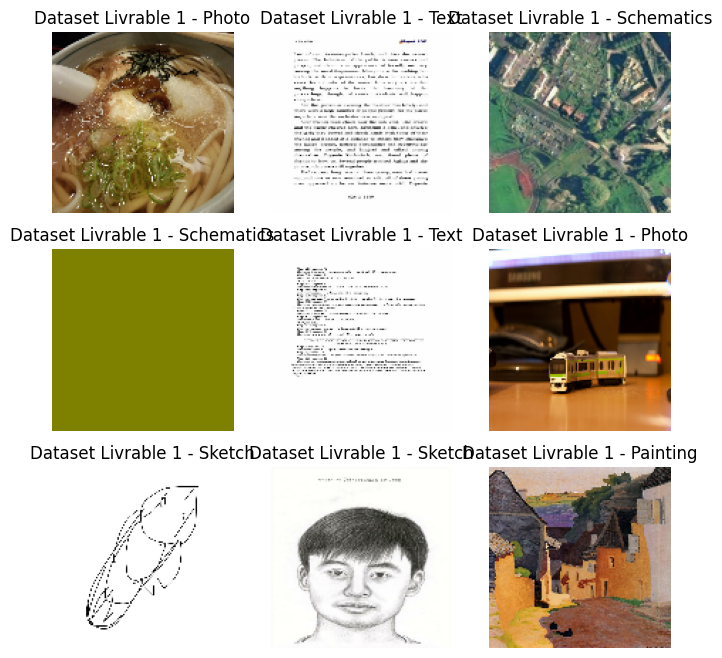

In [90]:
plt.figure(figsize=(8, 8))
for images, label in train_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i +1)
        ax.imshow(images[i].numpy().astype('uint8'))
        plt.title(labels[label[i]])
        plt.axis("off")

## Chargement des données dans le cache pour optimiser l'entraînement

In [91]:
def cast_to_uint8(images, labels):
    images = tf.cast(images, tf.uint8)
    return images, labels

In [92]:
AUTOTUNE = tf.data.experimental.AUTOTUNE

train_data = train_ds.map(cast_to_uint8, num_parallel_calls=tf.data.AUTOTUNE).cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_data = val_ds.map(cast_to_uint8, num_parallel_calls=tf.data.AUTOTUNE).cache().prefetch(buffer_size=AUTOTUNE)
test_data = test_ds.map(cast_to_uint8, num_parallel_calls=tf.data.AUTOTUNE).cache().prefetch(buffer_size=AUTOTUNE)

In [93]:
%pip install tqdm

import psutil
from tqdm import tqdm

process = psutil.Process(os.getpid())

def preload_and_cache(dataset, total_batches, split_name="Dataset"):
    initial_ram = process.memory_info().rss / (1024 ** 2)
    print(f"\n--- Caching {split_name} (RAM before: {initial_ram:.1f} MB) ---")
    
    for _ in tqdm(dataset, total=total_batches, desc=f"Loading {split_name}", unit="batch"):
        pass

    final_ram = process.memory_info().rss / (1024 ** 2)
    delta_ram = final_ram - initial_ram
    print(f"{split_name} cached. RAM used: {final_ram:.1f} MB (+{delta_ram:.1f} MB added)")

preload_and_cache(train_data, len(train_ds), "Train")
preload_and_cache(val_data, len(val_ds), "Validation")
preload_and_cache(test_data, len(test_ds), "Test")


[notice] A new release of pip is available: 23.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.

--- Caching Train (RAM before: 2856.6 MB) ---


Loading Train: 100%|██████████| 906/906 [00:44<00:00, 20.54batch/s] 


Train cached. RAM used: 3825.4 MB (+968.8 MB added)

--- Caching Validation (RAM before: 3825.4 MB) ---


Loading Validation: 100%|██████████| 194/194 [00:10<00:00, 19.29batch/s]


Validation cached. RAM used: 3904.6 MB (+79.2 MB added)

--- Caching Test (RAM before: 3904.6 MB) ---


Loading Test: 100%|██████████| 195/195 [00:18<00:00, 10.62batch/s]

Test cached. RAM used: 4096.7 MB (+192.1 MB added)


## Construction du modèle CNN

Un réseau de neurones convolutif (CNN) est utilisé car il est particulièrement adapté à l'analyse d'images.

Les couches de convolution permettent d'extraire progressivement des caractéristiques visuelles :
- contours ;
- textures ;
- formes ;
- motifs plus complexes.

Les couches de MaxPooling réduisent progressivement la résolution spatiale des représentations tout en conservant les informations les plus importantes.

Une couche Flatten transforme ensuite la représentation multidimensionnelle en vecteur afin de pouvoir utiliser des couches denses pour la classification.

La dernière couche contient un seul neurone associé à une fonction d'activation sigmoïde. Elle produit une probabilité comprise entre 0 et 1 correspondant à la probabilité que l'image appartienne à la classe « Photo ».

In [94]:
model_baseline = keras.Sequential([

    layers.Input(shape=(img_height, img_width, 3)),
    layers.Rescaling(1./255),
    layers.Conv2D(32, (3, 3),activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64,(3, 3),activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(128,(3, 3),activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(len(labels), activation="softmax")
])

model_baseline.summary()

model_baseline.compile(optimizer="adam", loss ='sparse_categorical_crossentropy', metrics=['accuracy'])

Model: "sequential_20"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_20 (Rescaling)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_58 (Conv2D)              │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_72 (MaxPooling2D) │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_59 (Conv2D)              │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_73 (MaxPooling2D) │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_60 (Conv2D)              │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_74 (MaxPooling2D) │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_17 (Flatten)            │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_33 (Dense)                │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_34 (Dense)                │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,285 (12.61 MB)

 Trainable params: 3,305,285 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [95]:
history_baseline = model_baseline.fit(
    train_data,
    validation_data=val_data,
    epochs=epochs,
    batch_size=batch_size,
)

Epoch 1/30
906/906 ━━━━━━━━━━━━━━━━━━━━ 446s 493ms/step - accuracy: 0.7890 - loss: 0.4994 - val_accuracy: 0.8204 - val_loss: 0.4528
Epoch 2/30
906/906 ━━━━━━━━━━━━━━━━━━━━ 473s 522ms/step - accuracy: 0.8695 - loss: 0.3225 - val_accuracy: 0.8858 - val_loss: 0.3096
Epoch 3/30
906/906 ━━━━━━━━━━━━━━━━━━━━ 427s 472ms/step - accuracy: 0.8976 - loss: 0.2575 - val_accuracy: 0.8932 - val_loss: 0.2979
Epoch 4/30
906/906 ━━━━━━━━━━━━━━━━━━━━ 461s 508ms/step - accuracy: 0.9199 - loss: 0.2016 - val_accuracy: 0.8932 - val_loss: 0.2911
Epoch 5/30
906/906 ━━━━━━━━━━━━━━━━━━━━ 462s 510ms/step - accuracy: 0.9455 - loss: 0.1443 - val_accuracy: 0.8930 - val_loss: 0.3201
Epoch 6/30
906/906 ━━━━━━━━━━━━━━━━━━━━ 429s 474ms/step - accuracy: 0.9602 - loss: 0.1068 - val_accuracy: 0.8882 - val_loss: 0.4052
Epoch 7/30
906/906 ━━━━━━━━━━━━━━━━━━━━ 410s 452ms/step - accuracy: 0.9711 - loss: 0.0800 - val_accuracy: 0.8855 - val_loss: 0.4698
Epoch 8/30
906/906 ━━━━━━━━━━━━━━━━━━━━ 406s 448ms/step - accuracy: 0.9796 -

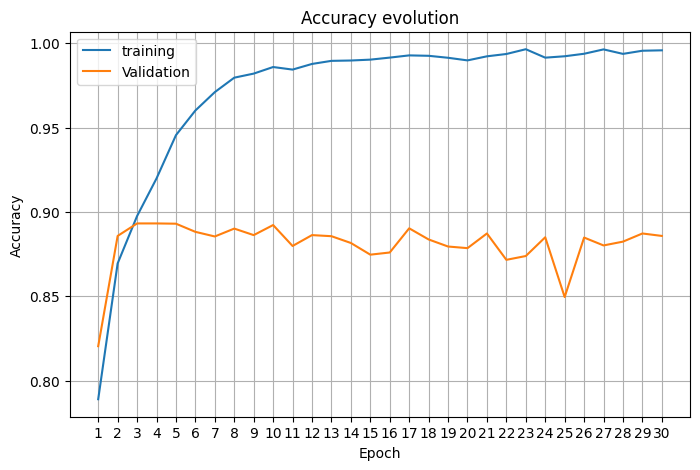

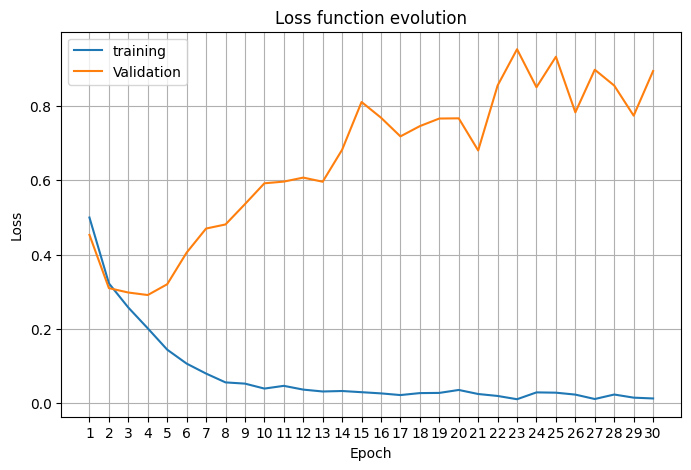

In [96]:
acc = history_baseline.history["accuracy"]
val_acc = history_baseline.history["val_accuracy"]
loss = history_baseline.history["loss"]
val_loss = history_baseline.history["val_loss"]
actual_epochs = range(1, epochs + 1)

# accuracy plots
plt.figure(figsize=(8, 5))
plt.plot(actual_epochs, acc, label="training")
plt.plot(actual_epochs, val_acc, label="Validation")
plt.title("Accuracy evolution")
plt.xticks(actual_epochs)
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

# loss plots
plt.figure(figsize=(8, 5))
plt.plot(actual_epochs, loss, label="training")
plt.plot(actual_epochs, val_loss, label="Validation")
plt.title("Loss function evolution")
plt.xticks(actual_epochs)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

In [97]:
print(f'final training loss: {loss[-1]}\nfinal validation loss: {val_loss[-1]}')
print(f'--- generalization gap: {abs(loss[-1] - val_loss[-1])} ---')
print(f'\nfinal training accuracy: {acc[-1]}\nfinal validation accuracy: {val_acc[-1]}')
print(f'--- accuracy gap: {abs(acc[-1] - val_acc[-1])} ---')

final training loss: 0.013089864514768124
final validation loss: 0.8932490348815918
--- generalization gap: 0.8801591703668237 ---

final training accuracy: 0.9958590865135193
final validation accuracy: 0.8857925534248352
--- accuracy gap: 0.11006653308868408 ---


In [98]:
model_baseline.save("model_baseline.keras")

On peut voir que le modèle est en surapprentissage, nous allons tester différentes techniques pour réduire l'erreur de généralisation

## 5 Techniques de régularisation

## 5.1 Dropout

In [99]:
model_with_dropout = keras.Sequential([
    layers.Input(shape=(img_height, img_width, 3)),
    layers.Rescaling(1./255),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.2),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(len(labels), activation="softmax"),
])

model_with_dropout.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

model_with_dropout.summary()

Model: "sequential_21"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_21 (Rescaling)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_61 (Conv2D)              │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_75 (MaxPooling2D) │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_62 (Conv2D)              │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_76 (MaxPooling2D) │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_63 (Conv2D)              │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_77 (MaxPooling2D) │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_16 (Dropout)            │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_18 (Flatten)            │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_35 (Dense)                │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_36 (Dense)                │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,285 (12.61 MB)

 Trainable params: 3,305,285 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
906/906 ━━━━━━━━━━━━━━━━━━━━ 407s 449ms/step - accuracy: 0.7661 - loss: 0.5503 - val_accuracy: 0.8333 - val_loss: 0.4189
Epoch 2/30
906/906 ━━━━━━━━━━━━━━━━━━━━ 437s 482ms/step - accuracy: 0.8606 - loss: 0.3441 - val_accuracy: 0.8768 - val_loss: 0.3061
Epoch 3/30
906/906 ━━━━━━━━━━━━━━━━━━━━ 423s 466ms/step - accuracy: 0.8872 - loss: 0.2849 - val_accuracy: 0.8793 - val_loss: 0.3078
Epoch 4/30
906/906 ━━━━━━━━━━━━━━━━━━━━ 404s 445ms/step - accuracy: 0.9127 - loss: 0.2250 - val_accuracy: 0.8731 - val_loss: 0.3465
Epoch 5/30
906/906 ━━━━━━━━━━━━━━━━━━━━ 407s 449ms/step - accuracy: 0.9289 - loss: 0.1851 - val_accuracy: 0.9016 - val_loss: 0.2778
Epoch 6/30
906/906 ━━━━━━━━━━━━━━━━━━━━ 421s 465ms/step - accuracy: 0.9469 - loss: 0.1435 - val_accuracy: 0.8984 - val_loss: 0.3032
Epoch 7/30
906/906 ━━━━━━━━━━━━━━━━━━━━ 430s 474ms/step - accuracy: 0.9592 - loss: 0.1092 - val_accuracy: 0.8969 - val_loss: 0.3361
Epoch 8/30
906/906 ━━━━━━━━━━━━━━━━━━━━ 445s 492ms/step - accuracy: 0.9674 -

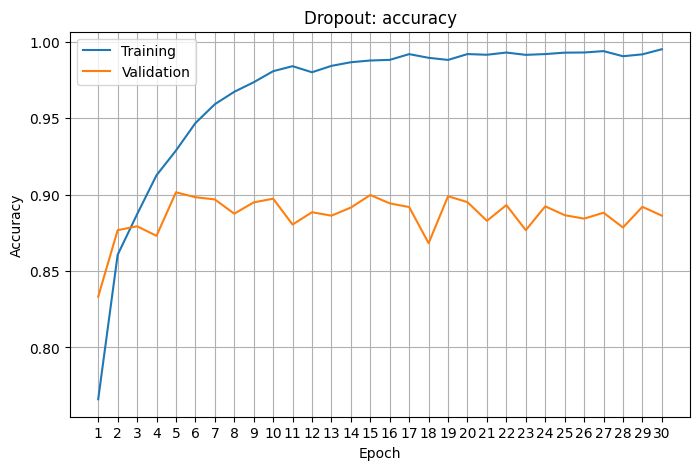

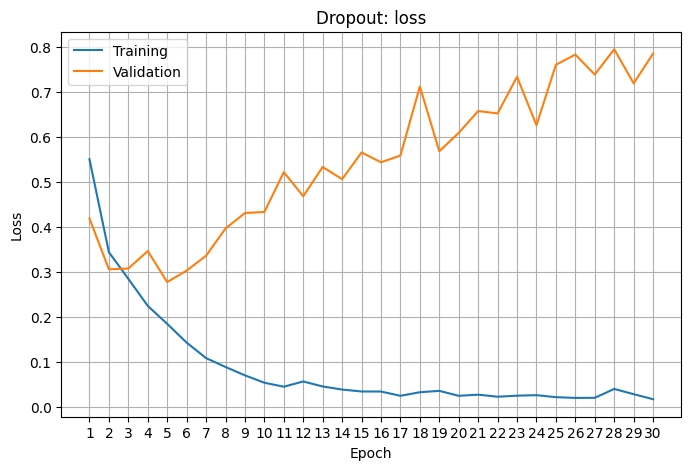

In [100]:
history_dropout = model_with_dropout.fit(
    train_data,
    validation_data=val_data,
    epochs=epochs,
    batch_size=batch_size,
)

dropout_acc = history_dropout.history["accuracy"]
dropout_val_acc = history_dropout.history["val_accuracy"]
dropout_loss = history_dropout.history["loss"]
dropout_val_loss = history_dropout.history["val_loss"]
dropout_epochs = range(1, len(dropout_acc) + 1)

plt.figure(figsize=(8, 5))
plt.plot(dropout_epochs, dropout_acc, label="Training")
plt.plot(dropout_epochs, dropout_val_acc, label="Validation")
plt.title("Dropout: accuracy")
plt.xticks(dropout_epochs)
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(dropout_epochs, dropout_loss, label="Training")
plt.plot(dropout_epochs, dropout_val_loss, label="Validation")
plt.title("Dropout: loss")
plt.xticks(dropout_epochs)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

In [101]:
print(f"Dropout - final training loss: {dropout_loss[-1]}")
print(f"Dropout - final validation loss: {dropout_val_loss[-1]}")
print(f"Dropout - final training accuracy: {dropout_acc[-1]}")
print(f"Dropout - final validation accuracy: {dropout_val_acc[-1]}")

Dropout - final training loss: 0.017969919368624687
Dropout - final validation loss: 0.7843985557556152
Dropout - final training accuracy: 0.9952724575996399
Dropout - final validation accuracy: 0.8862757682800293


In [102]:
model_with_dropout.save("model_with_dropout.keras")

## 5.2 Early Stopping

Model: "sequential_20"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_20 (Rescaling)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_58 (Conv2D)              │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_72 (MaxPooling2D) │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_59 (Conv2D)              │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_73 (MaxPooling2D) │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_60 (Conv2D)              │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_74 (MaxPooling2D) │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_17 (Flatten)            │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_33 (Dense)                │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_34 (Dense)                │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,285 (12.61 MB)

 Trainable params: 3,305,285 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
906/906 ━━━━━━━━━━━━━━━━━━━━ 391s 431ms/step - accuracy: 0.7560 - loss: 0.5679 - val_accuracy: 0.8294 - val_loss: 0.4066
Epoch 2/30
906/906 ━━━━━━━━━━━━━━━━━━━━ 420s 463ms/step - accuracy: 0.8568 - loss: 0.3534 - val_accuracy: 0.8632 - val_loss: 0.3395
Epoch 3/30
906/906 ━━━━━━━━━━━━━━━━━━━━ 418s 461ms/step - accuracy: 0.8860 - loss: 0.2849 - val_accuracy: 0.8808 - val_loss: 0.3114
Epoch 4/30
906/906 ━━━━━━━━━━━━━━━━━━━━ 377s 417ms/step - accuracy: 0.9150 - loss: 0.2198 - val_accuracy: 0.8863 - val_loss: 0.2948
Epoch 5/30
906/906 ━━━━━━━━━━━━━━━━━━━━ 374s 413ms/step - accuracy: 0.9341 - loss: 0.1730 - val_accuracy: 0.8926 - val_loss: 0.3080
Epoch 6/30
906/906 ━━━━━━━━━━━━━━━━━━━━ 388s 428ms/step - accuracy: 0.9535 - loss: 0.1252 - val_accuracy: 0.8922 - val_loss: 0.3354
Epoch 7/30
906/906 ━━━━━━━━━━━━━━━━━━━━ 417s 460ms/step - accuracy: 0.9667 - loss: 0.0890 - val_accuracy: 0.8940 - val_loss: 0.3626


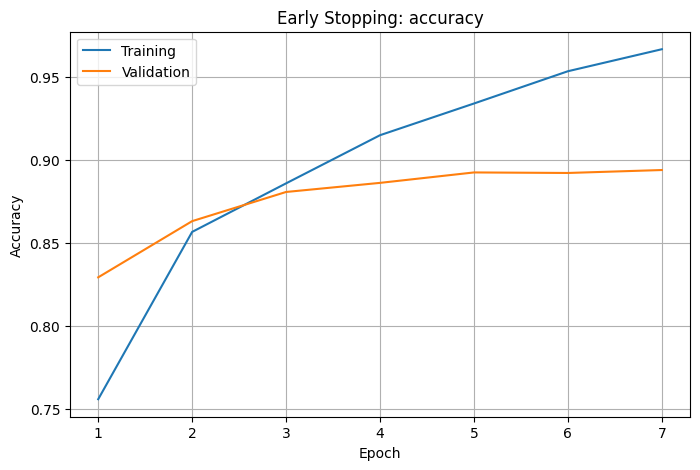

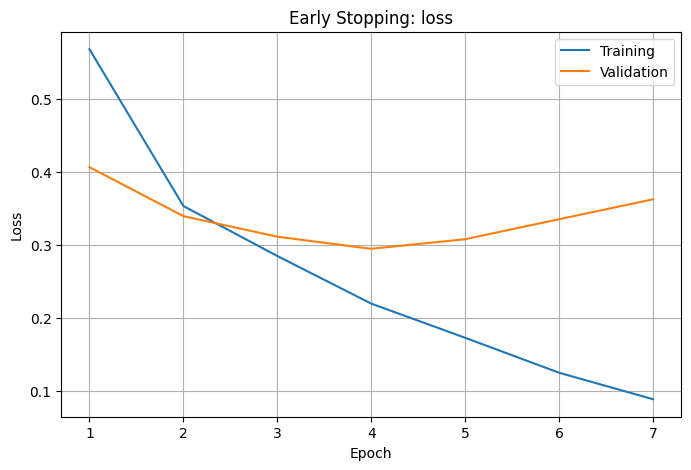

In [103]:
model_early_stopping = keras.models.clone_model(model_baseline)
model_early_stopping.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
model_early_stopping.summary()

early_stopping_callback = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
)

history_early_stopping = model_early_stopping.fit(
    train_data,
    validation_data=val_data,
    epochs=epochs,
    batch_size=batch_size,
    callbacks=[early_stopping_callback],
)

early_stopping_acc = history_early_stopping.history["accuracy"]
early_stopping_val_acc = history_early_stopping.history["val_accuracy"]
early_stopping_loss = history_early_stopping.history["loss"]
early_stopping_val_loss = history_early_stopping.history["val_loss"]
early_stopping_epochs = range(1, len(early_stopping_acc) + 1)

plt.figure(figsize=(8, 5))
plt.plot(early_stopping_epochs, early_stopping_acc, label="Training")
plt.plot(early_stopping_epochs,early_stopping_val_acc, label="Validation")
plt.title("Early Stopping: accuracy")
plt.xticks(early_stopping_epochs)
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(early_stopping_epochs,early_stopping_loss, label="Training")
plt.plot(early_stopping_epochs, early_stopping_val_loss, label="Validation")
plt.title("Early Stopping: loss")
plt.xticks(early_stopping_epochs)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

In [111]:
best_index_es = early_stopping_val_loss.index(min(early_stopping_val_loss))
print(f"Meilleure époque Early Stopping : {best_index_es + 1}")
print(f"Validation loss minimale : {early_stopping_val_loss[best_index_es]}")
print(f"Validation accuracy à cette époque : {early_stopping_val_acc[best_index_es]}")

Meilleure époque Early Stopping : 4
Validation loss minimale : 0.2948313355445862
Validation accuracy à cette époque : 0.8862757682800293


In [112]:
model_early_stopping.save("model_early_stopping.keras")